
# DemandPulse — Feature Engineering

## Objective
Prepare leakage-safe features for store-level retail sales forecasting.

## Dataset
Rossmann Store Sales dataset.

## Forecasting objective
Predict daily sales for the next seven calendar days.

## Planned work
1. Load and validate the raw data.
2. Create calendar features.
3. Integrate store metadata.
4. Create leakage-safe lag and rolling features.
5. Validate feature availability at forecast time.
6. Save the processed dataset and document decisions.


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path.home() / "Desktop" / "demandpulse"

train = pd.read_csv(
    PROJECT_DIR / "data" / "raw" / "train.csv"
)

store = pd.read_csv(
    PROJECT_DIR / "data" / "raw" / "store.csv"
)

train["Date"] = pd.to_datetime(train["Date"])

print("Train shape:", train.shape)
print("Store shape:", store.shape)

display(train.head())
display(store.head())

Train shape: (1017209, 9)
Store shape: (1115, 10)


/var/folders/c_/5mfnb9m14c5_4t_pchc84y0w0000gn/T/ipykernel_19814/1169534262.py:7: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv(


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [2]:
print("Training date range:")
print(train["Date"].min(), "to", train["Date"].max())

print("\nDuplicate training rows:", train.duplicated().sum())

print("\nMissing values in train:")
display(train.isnull().sum().to_frame("Missing values"))

print("\nMissing values in store:")
display(store.isnull().sum().to_frame("Missing values"))


Training date range:
2013-01-01 00:00:00 to 2015-07-31 00:00:00

Duplicate training rows: 0

Missing values in train:


,Missing values
Store,0
DayOfWeek,0
Date,0
Sales,0
Customers,0
Open,0
Promo,0
StateHoliday,0
SchoolHoliday,0



Missing values in store:


,Missing values
Store,0
StoreType,0
Assortment,0
CompetitionDistance,3
CompetitionOpenSinceMonth,354
CompetitionOpenSinceYear,354
Promo2,0
Promo2SinceWeek,544
Promo2SinceYear,544
PromoInterval,544


In [3]:
df = train.copy()

df["Date"] = pd.to_datetime(df["Date"])

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["WeekOfYear"] = (
    df["Date"].dt.isocalendar().week.astype(int)
)

display(
    df[
        [
            "Date",
            "Year",
            "Month",
            "Day",
            "DayOfWeek",
            "WeekOfYear",
            "Store",
            "Sales"
        ]
    ].head(10)
)

,Date,Year,Month,Day,DayOfWeek,WeekOfYear,Store,Sales
0,2015-07-31,2015,7,31,5,31,1,5263
1,2015-07-31,2015,7,31,5,31,2,6064
2,2015-07-31,2015,7,31,5,31,3,8314
3,2015-07-31,2015,7,31,5,31,4,13995
4,2015-07-31,2015,7,31,5,31,5,4822
5,2015-07-31,2015,7,31,5,31,6,5651
6,2015-07-31,2015,7,31,5,31,7,15344
7,2015-07-31,2015,7,31,5,31,8,8492
8,2015-07-31,2015,7,31,5,31,9,8565
9,2015-07-31,2015,7,31,5,31,10,7185


In [4]:
print("Unique stores in train:", df["Store"].nunique())
print("Unique stores in metadata:", store["Store"].nunique())

print("Duplicate store IDs:", store["Store"].duplicated().sum())

df = df.merge(
    store,
    on="Store",
    how="left",
    validate="many_to_one"
)

print("Merged shape:", df.shape)

display(df.head())

Unique stores in train: 1115
Unique stores in metadata: 1115
Duplicate store IDs: 0
Merged shape: (1017209, 22)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,Year,...,WeekOfYear,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,2015,...,31,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,2015,...,31,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,2015,...,31,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,2015,...,31,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,2015,...,31,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [5]:
print("Dataset shape:", df.shape)

print("\nMissing values after merge:")
display(
    df.isnull().sum()
       .sort_values(ascending=False)
       .head(15)
       .to_frame("Missing values")
)

print("\nStore type distribution:")
display(df["StoreType"].value_counts(dropna=False))

print("\nAssortment distribution:")
display(df["Assortment"].value_counts(dropna=False))

print("\nRows per store — sample:")
display(df.groupby("Store")["Date"].count().head(10))

Dataset shape: (1017209, 22)

Missing values after merge:


,Missing values
PromoInterval,508031
Promo2SinceYear,508031
Promo2SinceWeek,508031
CompetitionOpenSinceYear,323348
CompetitionOpenSinceMonth,323348
CompetitionDistance,2642
DayOfWeek,0
Promo2,0
Assortment,0
StoreType,0



Store type distribution:


StoreType
a    551627
d    312912
c    136840
b     15830
Name: count, dtype: int64


Assortment distribution:


Assortment
a    537445
c    471470
b      8294
Name: count, dtype: int64


Rows per store — sample:


Store
1     942
2     942
3     942
4     942
5     942
6     942
7     942
8     942
9     942
10    942
Name: Date, dtype: int64

In [7]:
print([
    col for col in df.columns
    if "Sales_lag" in col
])

[]


In [8]:
df = df.sort_values(
    ["Store", "Date"]
).reset_index(drop=True)

for lag in [7, 14, 28]:
    df[f"Sales_lag_{lag}"] = (
        df.groupby("Store")["Sales"].shift(lag)
    )

print("Lag features created.")

display(
    df[
        [
            "Store",
            "Date",
            "Sales",
            "Sales_lag_7",
            "Sales_lag_14",
            "Sales_lag_28"
        ]
    ].head(40)
)

Lag features created.


,Store,Date,Sales,Sales_lag_7,Sales_lag_14,Sales_lag_28
0,1,2013-01-01,0,NaN,NaN,NaN
1,1,2013-01-02,5530,NaN,NaN,NaN
2,1,2013-01-03,4327,NaN,NaN,NaN
3,1,2013-01-04,4486,NaN,NaN,NaN
4,1,2013-01-05,4997,NaN,NaN,NaN
5,1,2013-01-06,0,NaN,NaN,NaN
6,1,2013-01-07,7176,NaN,NaN,NaN
7,1,2013-01-08,5580,0.0,NaN,NaN
8,1,2013-01-09,5471,5530.0,NaN,NaN
9,1,2013-01-10,4892,4327.0,NaN,NaN


In [9]:
lag_columns = [
    "Sales_lag_7",
    "Sales_lag_14",
    "Sales_lag_28"
]

print("Missing values in lag features:")
display(df[lag_columns].isnull().sum())

print("\nRows with all lag features available:")
display(
    df.dropna(subset=lag_columns)[
        ["Store", "Date", "Sales"] + lag_columns
    ].head(10)
)

Missing values in lag features:


Sales_lag_7      7805
Sales_lag_14    15610
Sales_lag_28    31220
dtype: int64


Rows with all lag features available:


,Store,Date,Sales,Sales_lag_7,Sales_lag_14,Sales_lag_28
28,1,2013-01-29,3725,5720.0,3900.0,0.0
29,1,2013-01-30,4601,5578.0,4008.0,5530.0
30,1,2013-01-31,4709,5195.0,4044.0,4327.0
31,1,2013-02-01,5633,5586.0,4127.0,4486.0
32,1,2013-02-02,5970,5598.0,5182.0,4997.0
33,1,2013-02-03,0,0.0,0.0,0.0
34,1,2013-02-04,7032,4055.0,5394.0,7176.0
35,1,2013-02-05,6049,3725.0,5720.0,5580.0
36,1,2013-02-06,6140,4601.0,5578.0,5471.0
37,1,2013-02-07,5499,4709.0,5195.0,4892.0


In [11]:
df = df.sort_values(
    ["Store", "Date"]
).reset_index(drop=True)

for window in [7, 14, 28]:
    df[f"Sales_rolling_mean_{window}"] = (
        df.groupby("Store")["Sales"]
        .transform(
            lambda s: s.shift(7).rolling(
                window=window,
                min_periods=window
            ).mean()
        )
    )

display(
    df[
        [
            "Store",
            "Date",
            "Sales",
            "Sales_rolling_mean_7",
            "Sales_rolling_mean_14",
            "Sales_rolling_mean_28"
        ]
    ].head(50)
)


,Store,Date,Sales,Sales_rolling_mean_7,Sales_rolling_mean_14,Sales_rolling_mean_28
0,1,2013-01-01,0,NaN,NaN,NaN
1,1,2013-01-02,5530,NaN,NaN,NaN
2,1,2013-01-03,4327,NaN,NaN,NaN
3,1,2013-01-04,4486,NaN,NaN,NaN
4,1,2013-01-05,4997,NaN,NaN,NaN
5,1,2013-01-06,0,NaN,NaN,NaN
6,1,2013-01-07,7176,NaN,NaN,NaN
7,1,2013-01-08,5580,NaN,NaN,NaN
8,1,2013-01-09,5471,NaN,NaN,NaN
9,1,2013-01-10,4892,NaN,NaN,NaN


In [12]:
rolling_columns = [
    "Sales_rolling_mean_7",
    "Sales_rolling_mean_14",
    "Sales_rolling_mean_28"
]

display(
    df[rolling_columns].isnull().sum()
)

Sales_rolling_mean_7     14495
Sales_rolling_mean_14    22300
Sales_rolling_mean_28    37910
dtype: int64

In [13]:
feature_columns = [
    "Sales_lag_7",
    "Sales_lag_14",
    "Sales_lag_28",
    "Sales_rolling_mean_7",
    "Sales_rolling_mean_14",
    "Sales_rolling_mean_28"
]

display(
    df[feature_columns].isnull().sum().to_frame(
        "Missing Values"
    )
)

,Missing Values
Sales_lag_7,7805
Sales_lag_14,15610
Sales_lag_28,31220
Sales_rolling_mean_7,14495
Sales_rolling_mean_14,22300
Sales_rolling_mean_28,37910


In [14]:
date_gaps = (
    df.groupby("Store")["Date"]
    .diff()
    .dt.days
)

print("Date gap distribution:")
display(date_gaps.value_counts(dropna=False).sort_index())

print("\nNumber of gaps greater than one day:")
print((date_gaps > 1).sum())

Date gap distribution:


Date
1.0      1015914
185.0        180
NaN         1115
Name: count, dtype: int64


Number of gaps greater than one day:
180


In [15]:
gap_rows = df.loc[
    date_gaps > 1,
    ["Store", "Date"]
].copy()

gap_rows["GapDays"] = date_gaps[date_gaps > 1]

display(gap_rows.head(20))

print("Affected stores:", gap_rows["Store"].nunique())
print("Total large gaps:", len(gap_rows))

,Store,Date,GapDays
11850,13,2015-01-01,185.0
18260,20,2015-01-01,185.0
19960,22,2015-01-01,185.0
29196,32,2015-01-01,185.0
32780,36,2015-01-01,185.0
37306,41,2015-01-01,185.0
41832,46,2015-01-01,185.0
46358,51,2015-01-01,185.0
47116,52,2015-01-01,185.0
52584,58,2015-01-01,185.0


Affected stores: 180
Total large gaps: 180


In [16]:
gap_rows = df.loc[
    date_gaps > 1,
    ["Store", "Date"]
].copy()

gap_rows["PreviousDate"] = (
    gap_rows["Date"] -
    pd.to_timedelta(date_gaps[date_gaps > 1], unit="D")
)

gap_rows["GapDays"] = date_gaps[date_gaps > 1]

display(gap_rows.head(20))

,Store,Date,PreviousDate,GapDays
11850,13,2015-01-01,2014-06-30,185.0
18260,20,2015-01-01,2014-06-30,185.0
19960,22,2015-01-01,2014-06-30,185.0
29196,32,2015-01-01,2014-06-30,185.0
32780,36,2015-01-01,2014-06-30,185.0
37306,41,2015-01-01,2014-06-30,185.0
41832,46,2015-01-01,2014-06-30,185.0
46358,51,2015-01-01,2014-06-30,185.0
47116,52,2015-01-01,2014-06-30,185.0
52584,58,2015-01-01,2014-06-30,185.0


In [17]:
lag_columns = [
    "Sales_lag_7",
    "Sales_lag_14",
    "Sales_lag_28"
]

df = df.drop(columns=lag_columns, errors="ignore")

history = df[["Store", "Date", "Sales"]].copy()

In [18]:
for lag in [7, 14, 28]:

    lag_data = history.copy()

    lag_data["Date"] = (
        lag_data["Date"] + pd.Timedelta(days=lag)
    )

    lag_data = lag_data.rename(
        columns={"Sales": f"Sales_lag_{lag}"}
    )

    df = df.merge(
        lag_data,
        on=["Store", "Date"],
        how="left",
        validate="one_to_one"
    )

In [19]:
display(
    df[
        [
            "Store",
            "Date",
            "Sales",
            "Sales_lag_7",
            "Sales_lag_14",
            "Sales_lag_28"
        ]
    ].head(40)
)

,Store,Date,Sales,Sales_lag_7,Sales_lag_14,Sales_lag_28
0,1,2013-01-01,0,NaN,NaN,NaN
1,1,2013-01-02,5530,NaN,NaN,NaN
2,1,2013-01-03,4327,NaN,NaN,NaN
3,1,2013-01-04,4486,NaN,NaN,NaN
4,1,2013-01-05,4997,NaN,NaN,NaN
5,1,2013-01-06,0,NaN,NaN,NaN
6,1,2013-01-07,7176,NaN,NaN,NaN
7,1,2013-01-08,5580,0.0,NaN,NaN
8,1,2013-01-09,5471,5530.0,NaN,NaN
9,1,2013-01-10,4892,4327.0,NaN,NaN


In [20]:
display(
    df[lag_columns].isnull().sum().to_frame(
        "Missing Values"
    )
)

,Missing Values
Sales_lag_7,9065
Sales_lag_14,18130
Sales_lag_28,36260


In [21]:
rolling_columns = [
    "Sales_rolling_mean_7",
    "Sales_rolling_mean_14",
    "Sales_rolling_mean_28"
]

df = df.drop(
    columns=rolling_columns,
    errors="ignore"
)

In [22]:
history = df[["Store", "Date", "Sales"]].copy()

history = history.set_index(
    ["Store", "Date"]
).sort_index()

In [23]:
for window in [7, 14, 28]:

    rolling_values = []

    for lag in range(7, 7 + window):

        historical_dates = pd.MultiIndex.from_arrays(
            [
                df["Store"],
                df["Date"] - pd.Timedelta(days=lag)
            ],
            names=["Store", "Date"]
        )

        values = history.reindex(historical_dates)["Sales"]

        rolling_values.append(values.to_numpy())

    rolling_array = np.column_stack(rolling_values)

    df[f"Sales_rolling_mean_{window}"] = (
        np.where(
            ~np.isnan(rolling_array).any(axis=1),
            np.mean(rolling_array, axis=1),
            np.nan
        )
    )

In [24]:
rolling_columns = [
    "Sales_rolling_mean_7",
    "Sales_rolling_mean_14",
    "Sales_rolling_mean_28"
]

display(
    df[rolling_columns]
    .isnull()
    .sum()
    .to_frame("Missing Values")
)

,Missing Values
Sales_rolling_mean_7,16835
Sales_rolling_mean_14,25900
Sales_rolling_mean_28,44030


In [25]:
display(
    df[
        [
            "Store",
            "Date",
            "Sales",
            "Sales_rolling_mean_7",
            "Sales_rolling_mean_14",
            "Sales_rolling_mean_28"
        ]
    ].iloc[30:45]
)

,Store,Date,Sales,Sales_rolling_mean_7,Sales_rolling_mean_14,Sales_rolling_mean_28
30,1,2013-01-31,4709,4456.571429,4121.285714,NaN
31,1,2013-02-01,5633,4665.000000,4171.642857,NaN
32,1,2013-02-02,5970,4724.428571,4217.785714,NaN
33,1,2013-02-03,0,4724.428571,4217.785714,NaN
34,1,2013-02-04,7032,4533.142857,4170.500000,4121.285714
35,1,2013-02-05,6049,4248.142857,4158.000000,4254.321429
36,1,2013-02-06,6140,4108.571429,4200.357143,4221.142857
37,1,2013-02-07,5499,4039.142857,4247.857143,4234.785714
38,1,2013-02-08,5681,4045.857143,4355.428571,4275.750000
39,1,2013-02-09,5370,4099.000000,4411.714286,4310.500000


In [26]:
test_store = 1
forecast_origin = pd.Timestamp("2015-06-19")

test = df[
    (df["Store"] == test_store) &
    (df["Date"] >= forecast_origin - pd.Timedelta(days=35)) &
    (df["Date"] <= forecast_origin + pd.Timedelta(days=7))
][
    [
        "Store",
        "Date",
        "Sales",
        "Sales_lag_7",
        "Sales_lag_14",
        "Sales_lag_28",
        "Sales_rolling_mean_7"
    ]
]

display(test)

,Store,Date,Sales,Sales_lag_7,Sales_lag_14,Sales_lag_28,Sales_rolling_mean_7
864,1,2015-05-15,4178,4683.0,0.0,4718.0,4311.000000
865,1,2015-05-16,4431,4945.0,5850.0,4594.0,4181.714286
866,1,2015-05-17,0,0.0,0.0,0.0,4181.714286
867,1,2015-05-18,5280,3551.0,5591.0,3722.0,3890.285714
868,1,2015-05-19,5235,3547.0,4564.0,3037.0,3745.000000
869,1,2015-05-20,4735,3998.0,4960.0,3319.0,3607.571429
870,1,2015-05-21,3755,0.0,4529.0,3076.0,2960.571429
871,1,2015-05-22,4459,4178.0,4683.0,3198.0,2888.428571
872,1,2015-05-23,4276,4431.0,4945.0,4318.0,2815.000000
873,1,2015-05-24,0,0.0,0.0,0.0,2815.000000


In [27]:
future = df[
    (df["Store"] == 1) &
    (df["Date"] > forecast_origin) &
    (df["Date"] <= forecast_origin + pd.Timedelta(days=7))
].copy()

display(
    future[
        [
            "Store",
            "Date",
            "Sales",
            "Sales_lag_7",
            "Sales_lag_14",
            "Sales_lag_28",
            "Sales_rolling_mean_7"
        ]
    ]
)

,Store,Date,Sales,Sales_lag_7,Sales_lag_14,Sales_lag_28,Sales_rolling_mean_7
900,1,2015-06-20,4097,4256.0,4183.0,4276.0,3334.571429
901,1,2015-06-21,0,0.0,0.0,0.0,3334.571429
902,1,2015-06-22,3846,5518.0,4071.0,0.0,3541.285714
903,1,2015-06-23,3762,4852.0,4102.0,4211.0,3648.428571
904,1,2015-06-24,3346,4000.0,3591.0,4083.0,3706.857143
905,1,2015-06-25,3533,4645.0,3627.0,4111.0,3852.285714
906,1,2015-06-26,3317,4202.0,3695.0,4656.0,3924.714286


In [28]:
print("Total columns:", len(df.columns))

display(
    pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values
    })
)

Total columns: 28


,Column,Data Type
0,Store,int64
1,DayOfWeek,int64
2,Date,datetime64[ns]
3,Sales,int64
4,Customers,int64
5,Open,int64
6,Promo,int64
7,StateHoliday,object
8,SchoolHoliday,int64
9,Year,int32


In [29]:
target = "Sales"

categorical_features = [
    "Store",
    "DayOfWeek",
    "StateHoliday",
    "StoreType",
    "Assortment",
    "PromoInterval"
]

numerical_features = [
    "Promo",
    "SchoolHoliday",
    "Year",
    "Month",
    "Day",
    "WeekOfYear",
    "CompetitionDistance",
    "CompetitionOpenSinceMonth",
    "CompetitionOpenSinceYear",
    "Promo2",
    "Promo2SinceWeek",
    "Promo2SinceYear",
    "Sales_lag_7",
    "Sales_lag_14",
    "Sales_lag_28",
    "Sales_rolling_mean_7",
    "Sales_rolling_mean_14",
    "Sales_rolling_mean_28"
]

features = categorical_features + numerical_features

print("Total features:", len(features))
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

Total features: 24
Categorical features: 6
Numerical features: 18


In [30]:
missing = pd.DataFrame({
    "Missing_Count": df[features].isnull().sum(),
    "Missing_Percentage": (
        df[features].isnull().mean() * 100
    )
})

display(
    missing.sort_values(
        "Missing_Percentage",
        ascending=False
    ).round(2)
)

,Missing_Count,Missing_Percentage
PromoInterval,508031,49.94
Promo2SinceYear,508031,49.94
Promo2SinceWeek,508031,49.94
CompetitionOpenSinceMonth,323348,31.79
CompetitionOpenSinceYear,323348,31.79
Sales_rolling_mean_28,44030,4.33
Sales_lag_28,36260,3.56
Sales_rolling_mean_14,25900,2.55
Sales_lag_14,18130,1.78
Sales_rolling_mean_7,16835,1.66


In [31]:
# Promo2: no campaign information means no Promo2 campaign
df["PromoInterval"] = df["PromoInterval"].fillna("None")

df["Promo2SinceYear"] = df["Promo2SinceYear"].fillna(0)
df["Promo2SinceWeek"] = df["Promo2SinceWeek"].fillna(0)


# Create indicators before filling competition information
df["CompetitionMonthMissing"] = (
    df["CompetitionOpenSinceMonth"].isnull().astype(int)
)

df["CompetitionYearMissing"] = (
    df["CompetitionOpenSinceYear"].isnull().astype(int)
)

df["CompetitionDistanceMissing"] = (
    df["CompetitionDistance"].isnull().astype(int)
)


# Fill missing competition opening information
df["CompetitionOpenSinceMonth"] = (
    df["CompetitionOpenSinceMonth"].fillna(0)
)

df["CompetitionOpenSinceYear"] = (
    df["CompetitionOpenSinceYear"].fillna(0)
)


print("Remaining missing values in these columns:")

display(
    df[
        [
            "PromoInterval",
            "Promo2SinceYear",
            "Promo2SinceWeek",
            "CompetitionOpenSinceMonth",
            "CompetitionOpenSinceYear",
            "CompetitionDistance",
            "CompetitionMonthMissing",
            "CompetitionYearMissing",
            "CompetitionDistanceMissing"
        ]
    ].isnull().sum()
)

Remaining missing values in these columns:


PromoInterval                    0
Promo2SinceYear                  0
Promo2SinceWeek                  0
CompetitionOpenSinceMonth        0
CompetitionOpenSinceYear         0
CompetitionDistance           2642
CompetitionMonthMissing          0
CompetitionYearMissing           0
CompetitionDistanceMissing       0
dtype: int64

In [32]:
lag_rolling_columns = [
    "Sales_lag_7",
    "Sales_lag_14",
    "Sales_lag_28",
    "Sales_rolling_mean_7",
    "Sales_rolling_mean_14",
    "Sales_rolling_mean_28"
]

missing_history = pd.DataFrame({
    "Missing_Count": df[lag_rolling_columns].isnull().sum(),
    "Missing_Percentage": (
        df[lag_rolling_columns].isnull().mean() * 100
    )
})

display(missing_history.round(2))

,Missing_Count,Missing_Percentage
Sales_lag_7,9065,0.89
Sales_lag_14,18130,1.78
Sales_lag_28,36260,3.56
Sales_rolling_mean_7,16835,1.66
Sales_rolling_mean_14,25900,2.55
Sales_rolling_mean_28,44030,4.33


In [33]:
print(
    "Rows with at least one missing historical feature:",
    df[lag_rolling_columns].isnull().any(axis=1).sum()
)

print(
    "Total rows:",
    len(df)
)

Rows with at least one missing historical feature: 44030
Total rows: 1017209


In [34]:
print("Missing values in selected features:")

display(
    df[features].isnull().sum()
    .sort_values(ascending=False)
)

print("Missing values in target:")
print(df[target].isnull().sum())

Missing values in selected features:


Sales_rolling_mean_28        44030
Sales_lag_28                 36260
Sales_rolling_mean_14        25900
Sales_lag_14                 18130
Sales_rolling_mean_7         16835
Sales_lag_7                   9065
CompetitionDistance           2642
SchoolHoliday                    0
Promo2SinceWeek                  0
StateHoliday                     0
StoreType                        0
Assortment                       0
PromoInterval                    0
Promo                            0
Promo2SinceYear                  0
Promo2                           0
Year                             0
CompetitionOpenSinceYear         0
CompetitionOpenSinceMonth        0
DayOfWeek                        0
WeekOfYear                       0
Day                              0
Month                            0
Store                            0
dtype: int64

Missing values in target:
0


In [44]:
# Add missing indicators without creating duplicates
for col in [
    "CompetitionMonthMissing",
    "CompetitionYearMissing",
    "CompetitionDistanceMissing"
]:
    if col not in numerical_features:
        numerical_features.append(col)

# Recreate the complete feature list
features = categorical_features + numerical_features

print("Total features:", len(features))
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Total features: 27
Numerical features: 21
Categorical features: 6


In [35]:
target = "Sales"

X = df[features].copy()
y = df[target].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (1017209, 24)
Target shape: (1017209,)


In [52]:
for col in categorical_features:
    df[col] = df[col].astype(str)

In [53]:
target = "Sales"

X = df[features].copy()
y = df["Sales"].copy()

split_date = pd.Timestamp("2015-06-20")

train_mask = df["Date"] < split_date
valid_mask = df["Date"] >= split_date

X_train = X.loc[train_mask].copy()
X_valid = X.loc[valid_mask].copy()

y_train = y.loc[train_mask].copy()
y_valid = y.loc[valid_mask].copy()

print("Training shape:", X_train.shape)
print("Validation shape:", X_valid.shape)

Training shape: (970379, 27)
Validation shape: (46830, 27)


In [54]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [55]:
numerical_features = numerical_features + [
    "CompetitionMonthMissing",
    "CompetitionYearMissing",
    "CompetitionDistanceMissing"
]

In [56]:
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

In [57]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [58]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [59]:
X_train_processed = preprocessor.fit_transform(X_train)

X_valid_processed = preprocessor.transform(X_valid)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_valid_processed.shape)

Training shape: (970379, 1164)
Validation shape: (46830, 1164)


In [61]:
train_open_mask = df.loc[X_train.index, "Open"] == 1
valid_open_mask = df.loc[X_valid.index, "Open"] == 1

X_train_processed_open = X_train_processed[train_open_mask.to_numpy()]
X_valid_processed_open = X_valid_processed[valid_open_mask.to_numpy()]

y_train_open = y_train.loc[train_open_mask.index[train_open_mask]]
y_valid_open = y_valid.loc[valid_open_mask.index[valid_open_mask]]

print("Open training rows:", len(y_train_open))
print("Open validation rows:", len(y_valid_open))

print("Processed training shape:", X_train_processed_open.shape)
print("Processed validation shape:", X_valid_processed_open.shape)

Open training rows: 804110
Open validation rows: 40282
Processed training shape: (804110, 1164)
Processed validation shape: (40282, 1164)


In [62]:
from sklearn.ensemble import RandomForestRegressor

In [63]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=5,
    max_features="sqrt",
    n_jobs=-1,
    random_state=42
)

In [64]:
rf_model.fit(
    X_train_processed_open,
    y_train_open
)

RandomForestRegressor(max_depth=20, max_features='sqrt', min_samples_leaf=5,
                      n_jobs=-1, random_state=42)

In [67]:
rf_predictions = rf_model.predict(
    X_valid_processed_open
)

print("Predictions generated:", len(rf_predictions))
print("First 10 predictions:", rf_predictions[:10])

Predictions generated: 40282
First 10 predictions: [4325.18082767 4815.87548817 4413.45103263 4308.3239731  4445.57354431
 4513.94017936 4559.67530298 5967.11238098 5425.34808958 5453.78827411]


In [68]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_valid_open, rf_predictions)

rmse = np.sqrt(
    mean_squared_error(y_valid_open, rf_predictions)
)

wape = (
    np.sum(np.abs(y_valid_open - rf_predictions))
    / np.sum(np.abs(y_valid_open))
) * 100

bias = np.mean(rf_predictions - y_valid_open)

print("Random Forest Results")
print("---------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("WAPE:", round(wape, 2), "%")
print("Bias:", round(bias, 2))

Random Forest Results
---------------------
MAE: 863.37
RMSE: 1220.09
WAPE: 12.37 %
Bias: 101.43


In [69]:
import pandas as pd

feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(20))

,Feature,Importance
13,num__Sales_lag_14,0.165663
14,num__Sales_lag_28,0.138583
17,num__Sales_rolling_mean_28,0.125921
16,num__Sales_rolling_mean_14,0.116980
12,num__Sales_lag_7,0.097548
15,num__Sales_rolling_mean_7,0.089274
0,num__Promo,0.066236
1142,cat__DayOfWeek_1,0.017797
4,num__Day,0.015736
5,num__WeekOfYear,0.015269


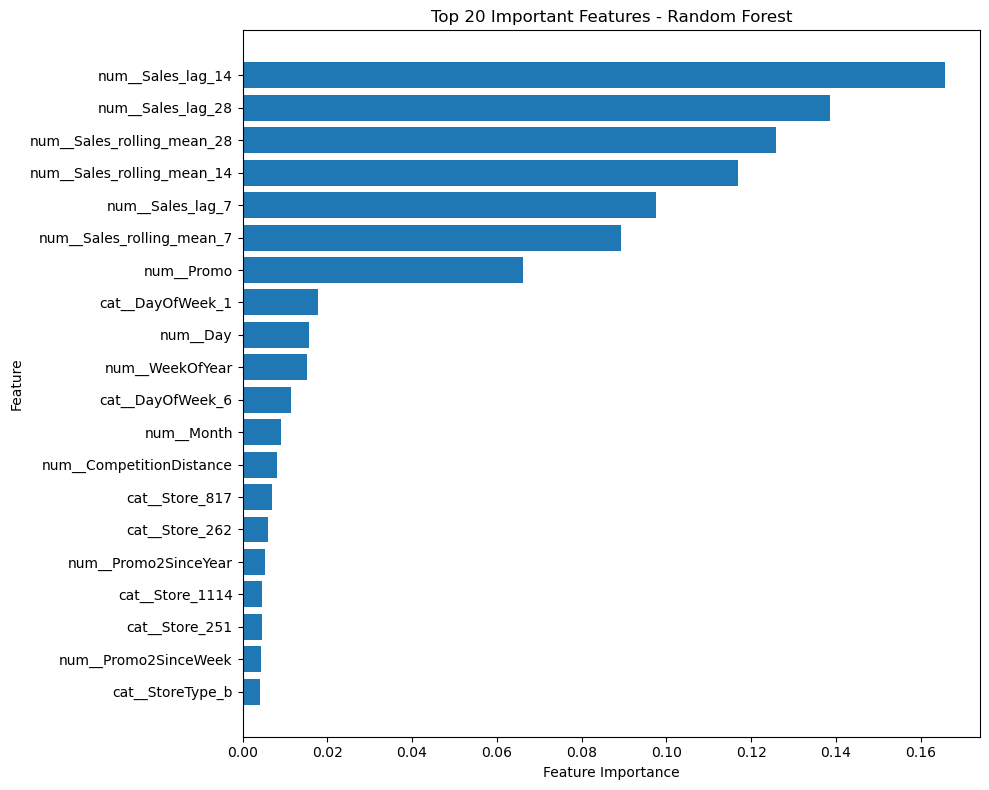

In [70]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(20).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Important Features - Random Forest")

plt.tight_layout()
plt.show()

In [72]:
%pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 2.8 MB/s  0:00:012.5 MB/s eta 0:00:01:01

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [73]:
import xgboost as xgb
from xgboost import XGBRegressor

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [74]:
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="reg:squarederror",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

In [75]:
xgb_model.fit(
    X_train_processed_open,
    y_train_open
)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=8,
             max_leaves=None, min_child_weight=5, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=-1, num_parallel_tree=None, ...)

In [76]:
xgb_predictions = xgb_model.predict(
    X_valid_processed_open
)

print("Predictions generated:", len(xgb_predictions))
print("First 10 predictions:", xgb_predictions[:10])

Predictions generated: 40282
First 10 predictions: [4238.991  3858.5625 3723.7683 3462.5503 3682.8142 3855.4387 4248.0137
 5662.249  6038.9565 6082.743 ]


In [77]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

xgb_mae = mean_absolute_error(
    y_valid_open, xgb_predictions
)

xgb_rmse = np.sqrt(
    mean_squared_error(y_valid_open, xgb_predictions)
)

xgb_wape = (
    np.sum(np.abs(y_valid_open - xgb_predictions))
    / np.sum(np.abs(y_valid_open))
) * 100

xgb_bias = np.mean(
    xgb_predictions - y_valid_open
)

print("XGBoost Results")
print("---------------------")
print("MAE:", round(xgb_mae, 2))
print("RMSE:", round(xgb_rmse, 2))
print("WAPE:", round(xgb_wape, 2), "%")
print("Bias:", round(xgb_bias, 2))

XGBoost Results
---------------------
MAE: 636.45
RMSE: 925.9
WAPE: 9.12 %
Bias: 115.8


In [78]:
comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "MAE": [mae, xgb_mae],
    "RMSE": [rmse, xgb_rmse],
    "WAPE": [wape, xgb_wape],
    "Bias": [bias, xgb_bias]
})

display(comparison.round(2))

,Model,MAE,RMSE,WAPE,Bias
0,Random Forest,863.37,1220.09,12.37,101.43
1,XGBoost,636.45,925.90,9.12,115.80


In [79]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

xgb_train_predictions = xgb_model.predict(
    X_train_processed_open
)

train_mae = mean_absolute_error(
    y_train_open,
    xgb_train_predictions
)

train_rmse = np.sqrt(
    mean_squared_error(
        y_train_open,
        xgb_train_predictions
    )
)

train_wape = (
    np.sum(np.abs(y_train_open - xgb_train_predictions))
    / np.sum(np.abs(y_train_open))
) * 100

print("XGBoost Training Results")
print("------------------------")
print("MAE:", round(train_mae, 2))
print("RMSE:", round(train_rmse, 2))
print("WAPE:", round(train_wape, 2), "%")

print("\nXGBoost Validation Results")
print("--------------------------")
print("MAE:", round(xgb_mae, 2))
print("RMSE:", round(xgb_rmse, 2))
print("WAPE:", round(xgb_wape, 2), "%")

XGBoost Training Results
------------------------
MAE: 547.44
RMSE: 789.85
WAPE: 7.87 %

XGBoost Validation Results
--------------------------
MAE: 636.45
RMSE: 925.9
WAPE: 9.12 %


In [80]:
import pandas as pd

split_date = pd.Timestamp("2015-06-20")

first_origin = split_date - pd.Timedelta(days=1)

last_origin = pd.Timestamp("2015-07-31") - pd.Timedelta(days=7)

origins = pd.date_range(
    start=first_origin,
    end=last_origin,
    freq="7D"
)

print("Number of forecast origins:", len(origins))
print("\nForecast origins:")

for origin in origins:
    print(
        origin.date(),
        "->",
        (origin + pd.Timedelta(days=1)).date(),
        "to",
        (origin + pd.Timedelta(days=7)).date()
    )

Number of forecast origins: 6

Forecast origins:
2015-06-19 -> 2015-06-20 to 2015-06-26
2015-06-26 -> 2015-06-27 to 2015-07-03
2015-07-03 -> 2015-07-04 to 2015-07-10
2015-07-10 -> 2015-07-11 to 2015-07-17
2015-07-17 -> 2015-07-18 to 2015-07-24
2015-07-24 -> 2015-07-25 to 2015-07-31


In [81]:
backtest_results = []

for origin in origins:

    train_data = df[df["Date"] <= origin].copy()

    valid_data = df[
        (df["Date"] > origin) &
        (df["Date"] <= origin + pd.Timedelta(days=7))
    ].copy()

    train_data = train_data[train_data["Open"] == 1]
    valid_data = valid_data[valid_data["Open"] == 1]

    print("Forecast origin:", origin.date())
    print("Training rows:", len(train_data))
    print("Validation rows:", len(valid_data))
    print("-" * 40)

Forecast origin: 2015-06-19
Training rows: 804110
Validation rows: 6717
----------------------------------------
Forecast origin: 2015-06-26
Training rows: 810827
Validation rows: 6720
----------------------------------------
Forecast origin: 2015-07-03
Training rows: 817547
Validation rows: 6717
----------------------------------------
Forecast origin: 2015-07-10
Training rows: 824264
Validation rows: 6708
----------------------------------------
Forecast origin: 2015-07-17
Training rows: 830972
Validation rows: 6710
----------------------------------------
Forecast origin: 2015-07-24
Training rows: 837682
Validation rows: 6710
----------------------------------------


In [82]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

backtest_results = []

for origin in origins:

    train_data = df[df["Date"] <= origin].copy()

    valid_data = df[
        (df["Date"] > origin) &
        (df["Date"] <= origin + pd.Timedelta(days=7))
    ].copy()

    train_data = train_data[train_data["Open"] == 1]
    valid_data = valid_data[valid_data["Open"] == 1]

    X_train_bt = train_data[features]
    y_train_bt = train_data[target]

    X_valid_bt = valid_data[features]
    y_valid_bt = valid_data[target]

    # Fit preprocessing only on training data
    preprocessor_bt = clone(preprocessor)

    X_train_bt_processed = preprocessor_bt.fit_transform(
        X_train_bt
    )

    X_valid_bt_processed = preprocessor_bt.transform(
        X_valid_bt
    )

    # Create a fresh XGBoost model
    model_bt = XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=8,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="reg:squarederror",
        tree_method="hist",
        n_jobs=-1,
        random_state=42
    )

    model_bt.fit(
        X_train_bt_processed,
        y_train_bt
    )

    predictions_bt = model_bt.predict(
        X_valid_bt_processed
    )

    # Calculate metrics
    mae_bt = mean_absolute_error(
        y_valid_bt,
        predictions_bt
    )

    rmse_bt = np.sqrt(
        mean_squared_error(
            y_valid_bt,
            predictions_bt
        )
    )

    wape_bt = (
        np.sum(np.abs(y_valid_bt - predictions_bt))
        / np.sum(np.abs(y_valid_bt))
    ) * 100

    bias_bt = np.mean(
        predictions_bt - y_valid_bt
    )

    backtest_results.append({
        "Origin": origin,
        "MAE": mae_bt,
        "RMSE": rmse_bt,
        "WAPE": wape_bt,
        "Bias": bias_bt
    })

    print("Completed:", origin.date())

Completed: 2015-06-19
Completed: 2015-06-26
Completed: 2015-07-03
Completed: 2015-07-10
Completed: 2015-07-17
Completed: 2015-07-24


In [83]:

backtest_df = pd.DataFrame(backtest_results)

backtest_df["Origin"] = (
    backtest_df["Origin"].dt.strftime("%Y-%m-%d")
)

display(backtest_df.round(2))

,Origin,MAE,RMSE,WAPE,Bias
0,2015-06-19,441.59,769.94,7.69,153.91
1,2015-06-26,910.19,1261.42,10.89,357.15
2,2015-07-03,728.16,1038.31,11.88,-19.46
3,2015-07-10,576.38,782.77,7.46,125.68
4,2015-07-17,493.37,678.77,8.31,-267.26
5,2015-07-24,690.78,919.97,8.66,87.92


In [84]:
metrics = ["MAE", "RMSE", "WAPE", "Bias"]

print("Average Backtesting Performance")
print("--------------------------------")

for metric in metrics:
    print(
        f"{metric}:",
        round(backtest_df[metric].mean(), 2)
    )

print("\nVariation across forecast windows")
print("--------------------------------")

for metric in metrics:
    print(
        f"{metric} standard deviation:",
        round(backtest_df[metric].std(), 2)
    )

Average Backtesting Performance
--------------------------------
MAE: 640.08
RMSE: 908.53
WAPE: 9.15
Bias: 72.99

Variation across forecast windows
--------------------------------
MAE standard deviation: 172.21
RMSE standard deviation: 214.16
WAPE standard deviation: 1.81
Bias standard deviation: 207.18


In [86]:
!pip install shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 544.4/544.4 kB 2.8 MB/s  0:00:00m 3.0 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [shap]

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [87]:
import shap
import matplotlib.pyplot as plt

In [88]:
X_shap = X_valid_processed_open[:500]

In [89]:
explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_shap)

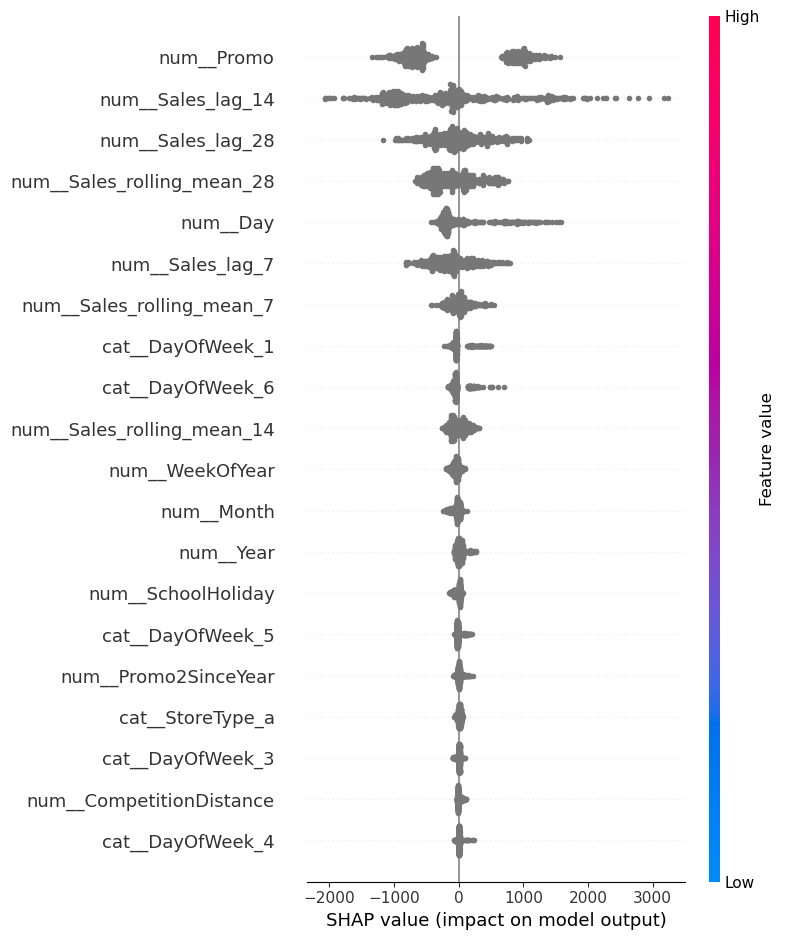

In [90]:
feature_names = preprocessor.get_feature_names_out()

shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    max_display=20
)

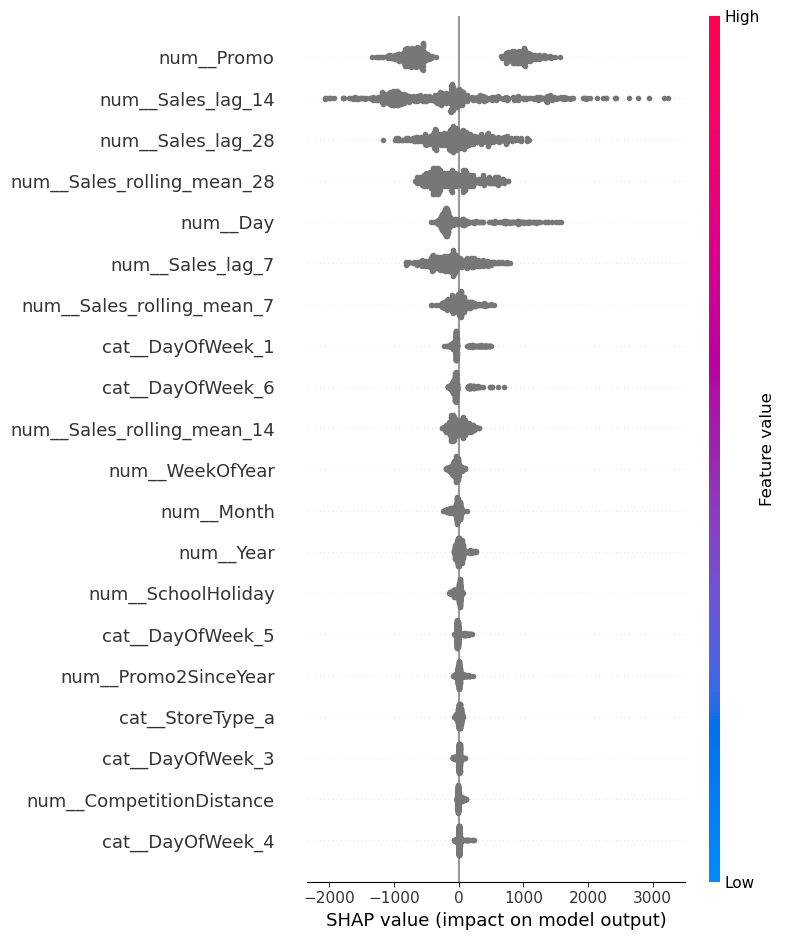

In [91]:
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    max_display=20,
    plot_type="dot",
    color_bar=True
)

In [92]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(xgb_model, "../models/xgboost_model.pkl")
joblib.dump(preprocessor, "../models/preprocessor.pkl")

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!


In [93]:
import joblib
from sklearn.pipeline import Pipeline

demandpulse_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", xgb_model)
])

joblib.dump(
    demandpulse_pipeline,
    "../models/demandpulse_pipeline.pkl"
)

print("DemandPulse pipeline saved successfully!")

DemandPulse pipeline saved successfully!


In [94]:
loaded_pipeline = joblib.load(
    "../models/demandpulse_pipeline.pkl"
)

print(loaded_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Promo', 'SchoolHoliday',
                                                   'Year', 'Month', 'Day',
                                                   'WeekOfYear',
                                                   'CompetitionDistance',
                                                   'CompetitionOpenSinceMonth',
                                                   'CompetitionOpenSinceYear',
                                                   'Promo2', 'Promo2SinceWeek',
                                                   'Promo2SinceYear',
                                                   'Sales_lag_7',
                                                   'Sales_lag_

In [95]:
import numpy as np
import joblib

loaded_pipeline = joblib.load(
    "../models/demandpulse_pipeline.pkl"
)

pipeline_predictions = loaded_pipeline.predict(X_valid)

original_predictions = xgb_model.predict(
    preprocessor.transform(X_valid)
)

print(
    "Predictions match:",
    np.allclose(pipeline_predictions, original_predictions)
)

print("\nFirst 5 predictions:")
print(pipeline_predictions[:5])

Predictions match: True

First 5 predictions:
[4238.991  3366.6875 3858.5625 3723.7683 3462.5503]
